# supplementary/LR_Regularization — TUNE-03

## Mục tiêu
Đánh giá tác động của C=1.0 trong quy trình LR theo người.

## Giả thuyết
Thay đổi cấu hình có thể cải thiện khả năng khái quát, nhưng mức thay đổi phụ thuộc từng người.

## Thiết lập
- 6.189 cửa sổ, 68 đặc trưng đầu vào và 15 người.
- Hai bài toán: multiclass và binary.
- Outer LOSO, inner GroupKFold 3 phần.
- Median, scaling và selection chỉ fit trên train trong từng lần CV.
- LR lbfgs, max_iter=2000, seed=42.
- Cấu hình lựa chọn dựa trên inner Macro-F1, outer test chỉ dùng đánh giá.
- Điểm tổng hợp là mean ± SD theo người, không phải theo cửa sổ.

In [ ]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/wesad/lr_workflow.py').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from wesad.lr_workflow import run_one
RUN_TRAIN = False
FOLDER = ROOT / 'experiments/supplementary/LR_Regularization/runs/TUNE-03'
if RUN_TRAIN:
    run_one('TUNE-03')


## Kết quả LOSO

In [ ]:
metrics = pd.read_csv(FOLDER / 'results.csv')
assert len(metrics) == 30
display(metrics.groupby('task')[['macro_f1', 'balanced_accuracy']].agg(['mean', 'std']))

      task  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  balanced_accuracy_std
    binary       0.893136      0.161183                0.904571               0.124064
multiclass       0.606986      0.188212                0.657269               0.152251


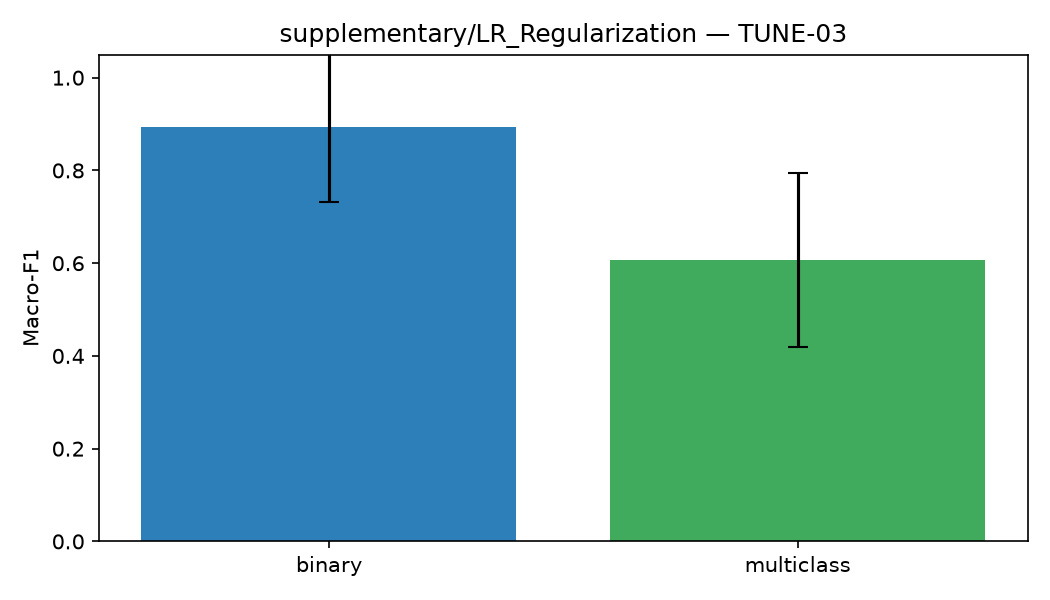

In [ ]:
display(Image(filename=str(FOLDER / 'summary_metrics.png')))

## Nhận xét
- binary: Macro-F1 0.893136 ± 0.161183; Balanced Accuracy 0.904571 ± 0.124064.
- multiclass: Macro-F1 0.606986 ± 0.188212; Balanced Accuracy 0.657269 ± 0.152251.

Kết quả tổng hợp không đồng nghĩa cải thiện trên mọi người. Đối chiếu `results.csv` theo subject và `fold_details.json` để xem đặc trưng, cảnh báo và cấu hình trong từng fold.

## Giới hạn
Dữ liệu chỉ gồm 15 người trong phòng thí nghiệm. Chưa có tập kiểm tra ngoài WESAD.

## Quyết định tiếp theo
Hoàn tất tập phương án đã định cho giai đoạn hiện tại. Chỉ chuyển bước khi đủ kết quả và kiểm tra chất lượng; không chọn cấu hình theo điểm outer test.